# New LinkedIn job-skills dataset: timeline and rising-jobs analysis

**Goal.** Before using this dataset as a test set alongside the 1.3M LinkedIn Jobs & Skills dataset, check
(1) what time window it covers, (2) whether posting volume rises or falls over time, and
(3) which kinds of jobs are *rising* within that window.

The folder actually holds two layers of data:

| File | What it is | Has dates? |
|---|---|---|
| `all_job_post (1).csv` | Kaggle **job-skill-set** (Batuhan Mutlu, 2024): 1,167 rows, 5 categories, with `job_skill_set` | No |
| `original_dataset/LinkedIn Job Postings (2023 - 2024)/postings.csv` | Its source: Arshkon's **LinkedIn Job Postings (2023-2024)** | Yes: `original_listed_time`, `listed_time`, `expiry`, `closed_time` (epoch ms) |

`all_job_post` has no date column, so this notebook joins it to `postings.csv` on `job_id` to recover posting dates.
The rising-jobs analysis (Part B) uses the full `postings.csv` plus its `jobs/` and `mappings/` side tables
(industries and job-function skills), because 1,167 rows are too few to find trends.

**How to run.** `pip install -e ".[notebooks]"`, then put the data under `data/raw/` (see the README) or set `JOB_SKILLS_DATA_DIR` to the folder that holds `all_job_post (1).csv` and `original_dataset/`. The saved outputs below come from the April 2024 snapshot.

In [1]:
import math
import os
from pathlib import Path

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({
    "figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})
RISE, FALL, NEUTRAL = "#2a78d6", "#eb6834", "#9a9893"

# Data folder: $JOB_SKILLS_DATA_DIR, or <repo>/data/raw when the notebook runs from notebooks/
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = Path(os.environ.get("JOB_SKILLS_DATA_DIR", REPO / "data" / "raw")).expanduser()
ROOT = f"{DATA_DIR}/original_dataset/LinkedIn Job Postings (2023 - 2024)/"
POSTINGS = ROOT + "postings.csv"
SKILLSET = DATA_DIR / "all_job_post (1).csv"
if not (Path(POSTINGS).is_file() and SKILLSET.is_file()):
    raise FileNotFoundError(f"Data not found under {DATA_DIR}. Set JOB_SKILLS_DATA_DIR or use data/raw/.")
TIME_COLS = ["original_listed_time", "listed_time", "expiry", "closed_time"]

# Part A. Timeline

## A1. Load data (only the needed columns; postings.csv is ~500 MB)

In [2]:
post = pd.read_csv(POSTINGS, usecols=["job_id", "title", "company_name", "formatted_experience_level",
                                      "formatted_work_type", "remote_allowed"] + TIME_COLS)
for c in TIME_COLS:
    post[c] = pd.to_datetime(post[c], unit="ms")

skill = pd.read_csv(SKILLSET)
print(f"postings.csv : {len(post):,} rows, {post.job_id.nunique():,} unique job_id")
print(f"all_job_post : {len(skill):,} rows, {skill.job_id.nunique():,} unique job_id")
print(skill.category.value_counts().to_string())

postings.csv : 123,849 rows, 123,849 unique job_id
all_job_post : 1,167 rows, 1,167 unique job_id
category
INFORMATION-TECHNOLOGY    240
BUSINESS-DEVELOPMENT      239
FINANCE                   236
SALES                     232
HR                        220


## A2. Range of each time field

- `original_listed_time`: when the job was **first** posted on LinkedIn
- `listed_time`: when it was (re)listed; in practice close to when it was scraped
- `expiry`: expiry date; `closed_time`: when it was closed (mostly empty)

In [3]:
rng = pd.DataFrame({
    "non_null": post[TIME_COLS].notna().sum(),
    "earliest": post[TIME_COLS].min(),
    "latest": post[TIME_COLS].max(),
})
rng["span_days"] = (rng["latest"] - rng["earliest"]).dt.days
rng

,non_null,earliest,latest,span_days
original_listed_time,123849,2023-12-05 21:08:53,2024-04-20 00:26:43,136
listed_time,123849,2024-03-24 21:50:14,2024-04-20 00:26:56,26
expiry,123849,2024-04-12 06:30:48,2024-10-17 00:26:36,187
closed_time,1073,2024-04-05 19:38:52,2024-04-19 21:28:27,14


## A3. Monthly counts by `original_listed_time`: almost everything is April 2024

original_listed_time
2023-12         3
2024-01         7
2024-02         9
2024-03      1815
2024-04    122015
Freq: M

Share in 2024-04: 98.5%


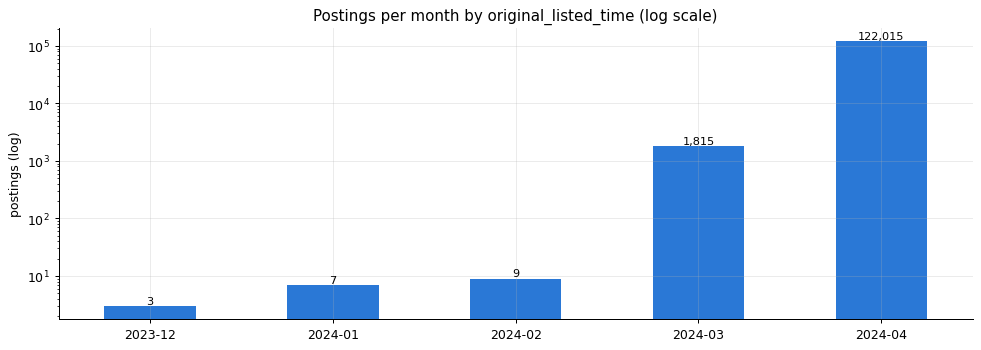

In [4]:
by_month = post.original_listed_time.dt.to_period("M").value_counts().sort_index()
print(by_month.to_string())
print(f"\nShare in 2024-04: {by_month.get(pd.Period('2024-04'), 0) / len(post):.1%}")

ax = by_month.plot(kind="bar", color=RISE, logy=True, rot=0)
ax.set_title("Postings per month by original_listed_time (log scale)")
ax.set_xlabel(""); ax.set_ylabel("postings (log)")
for i, v in enumerate(by_month.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## A4. Daily counts (`listed_time` vs `original_listed_time`)

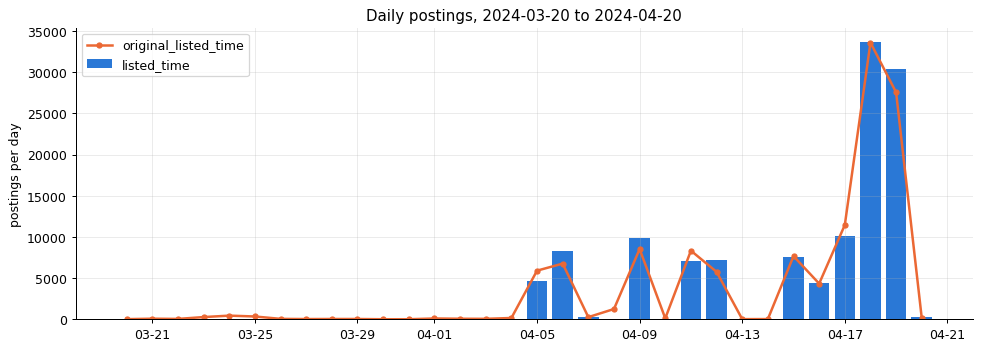

,listed_time,original_listed_time
2024-04-01 (Mon),0,93
2024-04-02 (Tue),0,61
2024-04-03 (Wed),0,51
2024-04-04 (Thu),0,153
2024-04-05 (Fri),4630,5901
2024-04-06 (Sat),8284,6758
2024-04-07 (Sun),222,256
2024-04-08 (Mon),0,1243
2024-04-09 (Tue),9924,8526
2024-04-10 (Wed),0,110


In [5]:
def daily(s, start=None, end=None):
    d = s.dt.floor("D").value_counts().sort_index()
    idx = pd.date_range(start or d.index.min(), end or d.index.max(), freq="D")
    return d.reindex(idx, fill_value=0)

start, end = pd.Timestamp("2024-03-20"), pd.Timestamp("2024-04-20")
d_list = daily(post.listed_time, start, end)
d_orig = daily(post.original_listed_time[post.original_listed_time >= start], start, end)

fig, ax = plt.subplots()
ax.bar(d_list.index, d_list.values, width=0.8, color=RISE, label="listed_time")
ax.plot(d_orig.index, d_orig.values, color=FALL, lw=2, marker="o", ms=4, label="original_listed_time")
ax.set_title("Daily postings, 2024-03-20 to 2024-04-20")
ax.set_ylabel("postings per day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.legend(); plt.tight_layout(); plt.show()

tbl = pd.DataFrame({"listed_time": d_list, "original_listed_time": d_orig})
tbl.index = tbl.index.strftime("%Y-%m-%d (%a)")
tbl.loc["2024-04-01 (Mon)":]

## A5. Gaps: days inside the coverage window with zero records

In [6]:
core = daily(post.listed_time[post.listed_time >= "2024-04-01"])
gaps = core[core == 0]
print(f"Main listed_time window: {core.index.min().date()} -> {core.index.max().date()} ({len(core)} days)")
print(f"Days with 0 records ({len(gaps)}):")
for d in gaps.index:
    print("  ", d.strftime("%Y-%m-%d %a"))
print("Note: original_listed_time is NOT zero on these days (e.g. 04-08), so jobs were still being posted;"
      " the scraper simply did not run.")

top2 = core.sort_values(ascending=False).head(2)
print(f"\nTwo largest days: {', '.join(f'{d.date()} ({v:,})' for d, v in top2.items())}"
      f" -> {top2.sum() / len(post):.1%} of all rows")

Main listed_time window: 2024-04-05 -> 2024-04-20 (16 days)
Days with 0 records (4):
   2024-04-08 Mon
   2024-04-10 Wed
   2024-04-13 Sat
   2024-04-14 Sun
Note: original_listed_time is NOT zero on these days (e.g. 04-08), so jobs were still being posted; the scraper simply did not run.

Two largest days: 2024-04-18 (33,721), 2024-04-19 (30,448) -> 51.8% of all rows


## A6. Weekly counts and cumulative curve

listed_time
2024-04-01/2024-04-07    13136
2024-04-08/2024-04-14    24214
2024-04-15/2024-04-21    86498
Freq: W-SUN


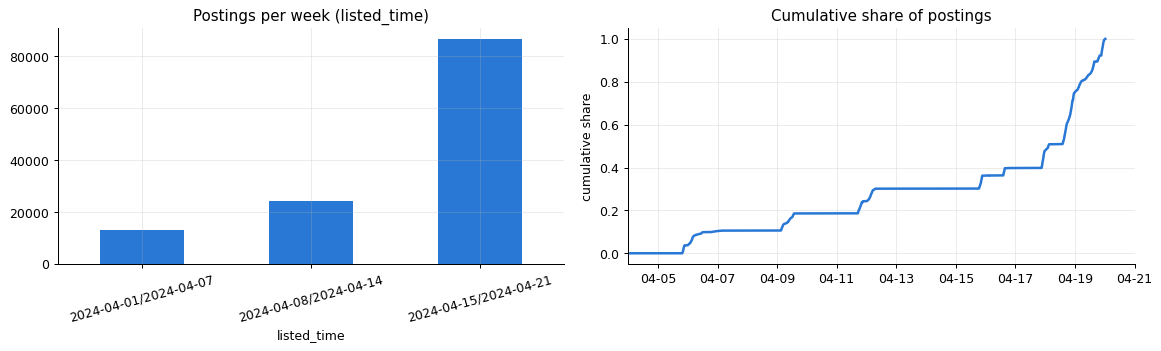

In [7]:
wk = post.listed_time[post.listed_time >= "2024-04-01"].dt.to_period("W-SUN").value_counts().sort_index()
print(wk.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
wk.index = wk.index.astype(str)
wk.plot(kind="bar", ax=axes[0], color=RISE, rot=15)
axes[0].set_title("Postings per week (listed_time)")

cum = post.listed_time.sort_values().reset_index(drop=True)
axes[1].plot(cum.values, np.arange(1, len(cum) + 1) / len(cum), color=RISE, lw=2)
axes[1].set_xlim(pd.Timestamp("2024-04-04"), pd.Timestamp("2024-04-21"))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[1].set_title("Cumulative share of postings")
axes[1].set_ylabel("cumulative share")
plt.tight_layout(); plt.show()

## A7. Sanity check: do `job_id` and posting time agree?

LinkedIn `job_id`s grow roughly monotonically with creation time. If `job_id` tracks `original_listed_time`,
the time field is trustworthy, and the step pattern above comes from batch scraping.

Spearman(job_id, original_listed_time) = 0.7978
Unusually small ids (job_id < 3.8e9): 366
job_id range: 921,716 -> 3,906,267,224


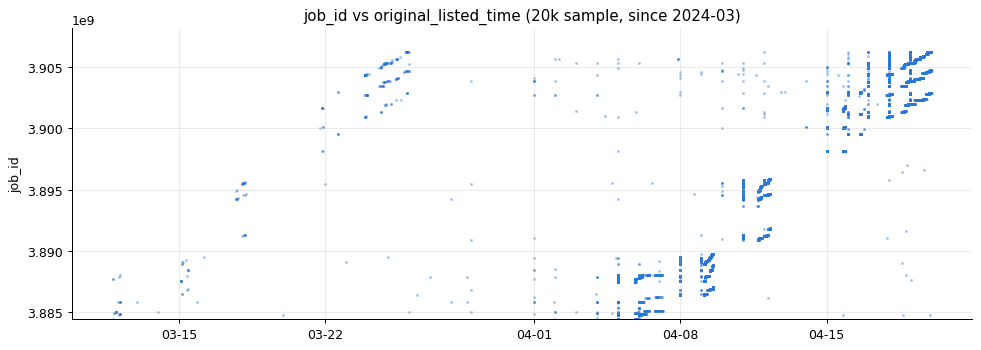

In [8]:
s = post.sample(min(20000, len(post)), random_state=0)
s = s[s.original_listed_time >= "2024-03-01"]
fig, ax = plt.subplots()
ax.scatter(s.original_listed_time, s.job_id, s=2, alpha=0.3, color=RISE)
ax.set_title("job_id vs original_listed_time (20k sample, since 2024-03)")
ax.set_ylim(s.job_id.quantile(0.01), s.job_id.max() * 1.0005)  # hide a few tiny legacy ids
ax.set_ylabel("job_id"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
plt.tight_layout(); plt.show()

print("Spearman(job_id, original_listed_time) =",
      round(post.job_id.rank().corr(post.original_listed_time.rank()), 4))
print(f"Unusually small ids (job_id < 3.8e9): {(post.job_id < 3.8e9).sum():,}")
print("job_id range:", f"{post.job_id.min():,} -> {post.job_id.max():,}")

## A8. Timeline of `all_job_post` (the job-skill-set subset)

job_ids found in postings.csv: 1,167 / 1,167
listed_time range: 2024-04-05 19:34:58 -> 2024-04-20 00:24:39
original_listed_time range: 2024-03-11 20:31:26 -> 2024-04-20 00:24:39


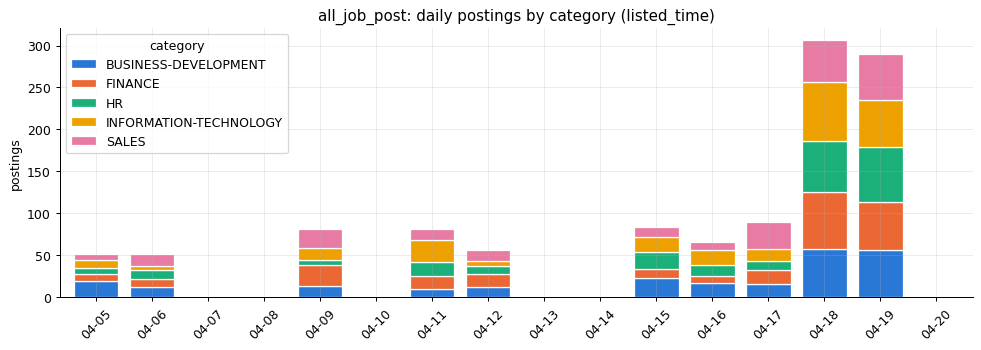

,04-05,04-06,04-07,04-08,04-09,04-10,04-11,04-12,04-13,04-14,04-15,04-16,04-17,04-18,04-19,04-20
all_job_post share,0.045,0.045,0.003,0.0,0.07,0.0,0.070,0.048,0.0,0.0,0.072,0.057,0.077,0.262,0.249,0.003
postings.csv share,0.037,0.067,0.002,0.0,0.08,0.0,0.057,0.059,0.0,0.0,0.061,0.036,0.082,0.272,0.246,0.002


In [9]:
sk = skill.merge(post, on="job_id", how="left")
print(f"job_ids found in postings.csv: {sk.listed_time.notna().sum():,} / {len(sk):,}")
print("listed_time range:", sk.listed_time.min(), "->", sk.listed_time.max())
print("original_listed_time range:", sk.original_listed_time.min(), "->", sk.original_listed_time.max())

sd = daily(sk.listed_time, "2024-04-05", "2024-04-20")
by_cat = (sk.assign(day=sk.listed_time.dt.floor("D"))
            .pivot_table(index="day", columns="category", values="job_id", aggfunc="count")
            .reindex(sd.index, fill_value=0).fillna(0))
fig, ax = plt.subplots(figsize=(11, 4))
by_cat.plot(kind="bar", stacked=True, ax=ax, rot=45, width=0.8, edgecolor="white", linewidth=1)
ax.set_xticklabels([d.strftime("%m-%d") for d in by_cat.index])
ax.set_title("all_job_post: daily postings by category (listed_time)")
ax.set_ylabel("postings"); plt.tight_layout(); plt.show()

cmp = pd.DataFrame({"all_job_post share": sd / sd.sum(),
                    "postings.csv share": daily(post.listed_time, "2024-04-05", "2024-04-20")
                                          / (post.listed_time >= "2024-04-05").sum()}).round(3)
cmp.index = cmp.index.strftime("%m-%d")
cmp.T

# Part B. Time-series analysis: which jobs are rising?

### Read this first: what "rising" can and cannot mean here

- The data covers **~2 weeks (2024-04-05 to 04-19)** with only **11 scrape days**, and raw daily counts are driven by
  how much the scraper collected that day (04-18 and 04-19 alone are ~52% of rows). **Raw counts therefore cannot show
  rising demand.**
- So every series below is a **share**: for each scrape day, the fraction of that day's postings that belong to a group
  (an industry, a job function, a title...). A group is "rising" if its share grows over the window.
- Two weeks is far too short for seasonality or labour-market trends. A rising share here more likely reflects
  **what the scraper picked up** (different search queries per batch) or **one employer bulk-posting**, not demand.
  Section B6 checks for the employer effect, and B7 checks robustness with a second date field.
- Treat Part B as a description of *composition shifts inside this snapshot*, useful for understanding the test set,
  not as a labour-market finding.

### Method
1. Restrict to `listed_time` in 2024-04-05..04-19 and split into **early** (04-05..04-12, 6 scrape days) and **late**
   (04-17..04-19, 3 scrape days); mid days (04-15, 04-16) are used only in the daily lines.
2. For each group: early share, late share, `log2(late/early)` (+1 = share doubled), and a two-proportion z-test (an unadjusted, exploratory p-value: postings cluster by employer and many groups are tested).
3. Keep groups with enough postings, and report **Spearman ρ** between scrape-day index and daily share
   (does it rise steadily, or jump only on the big days?).

In [10]:
win = post[(post.listed_time >= "2024-04-05") & (post.listed_time < "2024-04-20")].copy()
win["day"] = win.listed_time.dt.floor("D")
win["period"] = np.select([win.day <= "2024-04-12", win.day >= "2024-04-17"], ["early", "late"], "mid")
DAYS = sorted(win.day.unique())
print(win.period.value_counts().to_string())
print("Scrape days:", [pd.Timestamp(d).strftime("%m-%d") for d in DAYS])

# side tables
ind = (pd.read_csv(ROOT + "jobs/job_industries.csv")
         .merge(pd.read_csv(ROOT + "mappings/industries.csv"), on="industry_id"))
fun = (pd.read_csv(ROOT + "jobs/job_skills.csv")
         .merge(pd.read_csv(ROOT + "mappings/skills.csv"), on="skill_abr"))
print(f"industry links: {len(ind):,} | job-function links: {len(fun):,}")

period
late     74276
early    37350
mid      11917
Scrape days: ['04-05', '04-06', '04-07', '04-09', '04-11', '04-12', '04-15', '04-16', '04-17', '04-18', '04-19']
industry links: 164,808 | job-function links: 213,768


In [11]:
N_PERIOD = win.groupby("period").job_id.nunique()
N_DAY = win.groupby("day").job_id.nunique()

def _p_two_prop(x1, n1, x2, n2):
    p = (x1 + x2) / (n1 + n2)
    se = math.sqrt(p * (1 - p) * (1 / n1 + 1 / n2)) or 1e-12
    z = (x2 / n2 - x1 / n1) / se
    return math.erfc(abs(z) / math.sqrt(2))

def rising_table(df, col, min_n=200):
    """df: one row per (job_id, group). Shares are per scrape window / day, denominators = all postings."""
    df = df.drop_duplicates(["job_id", col])
    cnt = pd.crosstab(df[col], df.period).reindex(columns=["early", "mid", "late"], fill_value=0)
    cnt = cnt[(cnt.early + cnt.late) >= min_n]
    out = pd.DataFrame(index=cnt.index)
    out["n_early"], out["n_late"] = cnt.early, cnt.late
    out["share_early_%"] = 100 * cnt.early / N_PERIOD["early"]
    out["share_late_%"] = 100 * cnt.late / N_PERIOD["late"]
    out["log2_ratio"] = np.log2((cnt.late + 0.5) / N_PERIOD["late"]) - np.log2((cnt.early + 0.5) / N_PERIOD["early"])
    out["p_value"] = [_p_two_prop(e, N_PERIOD["early"], l, N_PERIOD["late"]) for e, l in zip(cnt.early, cnt.late)]
    daily_share = (df[df[col].isin(cnt.index)].groupby([col, "day"]).job_id.nunique()
                     .unstack(fill_value=0).reindex(columns=N_DAY.index, fill_value=0) / N_DAY)
    idx = pd.Series(np.arange(len(N_DAY)), index=N_DAY.index)
    out["spearman_rho"] = daily_share.apply(lambda r: r.rank().corr(idx.rank()), axis=1)
    return out.sort_values("log2_ratio", ascending=False).round(4), daily_share

def plot_movers(tab, title, k=10):
    top = pd.concat([tab.head(k), tab.tail(k)]).drop_duplicates()
    top = top.sort_values("log2_ratio")
    fig, ax = plt.subplots(figsize=(10, 0.32 * len(top) + 1))
    colors = [RISE if v > 0 else FALL for v in top.log2_ratio]
    ax.barh(top.index.astype(str), top.log2_ratio, color=colors, height=0.7)
    ax.axvline(0, color=NEUTRAL, lw=1)
    ax.set_xlabel("log2(late share / early share)   (+1 = share doubled, -1 = halved)")
    ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_daily_share(daily_share, groups, title):
    fig, ax = plt.subplots()
    for g in groups:
        ax.plot(daily_share.columns, 100 * daily_share.loc[g], marker="o", ms=5, lw=2, label=g)
    ax.set_ylabel("% of that day's postings")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    ax.set_title(title); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
    plt.tight_layout(); plt.show()

## B1. Industries

94 industries with >= 200 postings in early+late


,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
industry_name,,,,,,,
Wireless Services,35,178,0.0937,0.2396,1.3382,0.0000,0.2091
Computer and Network Security,141,671,0.3775,0.9034,1.2548,0.0000,0.5273
Engineering Services,147,654,0.3936,0.8805,1.1579,0.0000,0.2455
Retail Office Equipment,55,214,0.1473,0.2881,0.9586,0.0000,0.6273
Wellness and Fitness Services,309,1098,0.8273,1.4783,0.8357,0.0000,0.3818
Professional Services,81,287,0.2169,0.3864,0.8269,0.0000,0.6545
Semiconductor Manufacturing,100,352,0.2677,0.4739,0.8186,0.0000,0.3182
Advertising Services,387,1261,1.0361,1.6977,0.7111,0.0000,0.4000
Information Technology & Services,121,392,0.3240,0.5278,0.6999,0.0000,0.5182


,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
industry_name,,,,,,,
Computers and Electronics Manufacturing,97,146,0.2597,0.1966,-0.4044,0.0327,-0.3091
Primary and Secondary Education,198,285,0.5301,0.3837,-0.4674,0.0004,-0.0273
Airlines and Aviation,202,289,0.5408,0.3891,-0.4761,0.0003,0.0545
Staffing and Recruiting,3138,4469,8.4016,6.0167,-0.4817,0.0000,-0.4364
Renewable Energy Semiconductor Manufacturing,103,128,0.2758,0.1723,-0.6797,0.0003,-0.0182
Personal Care Product Manufacturing,142,121,0.3802,0.1629,-1.2218,0.0000,-0.2182
Public Safety,177,127,0.4739,0.1710,-1.4691,0.0000,-0.4545
Business Content,155,102,0.4150,0.1373,-1.5931,0.0000,0.0636


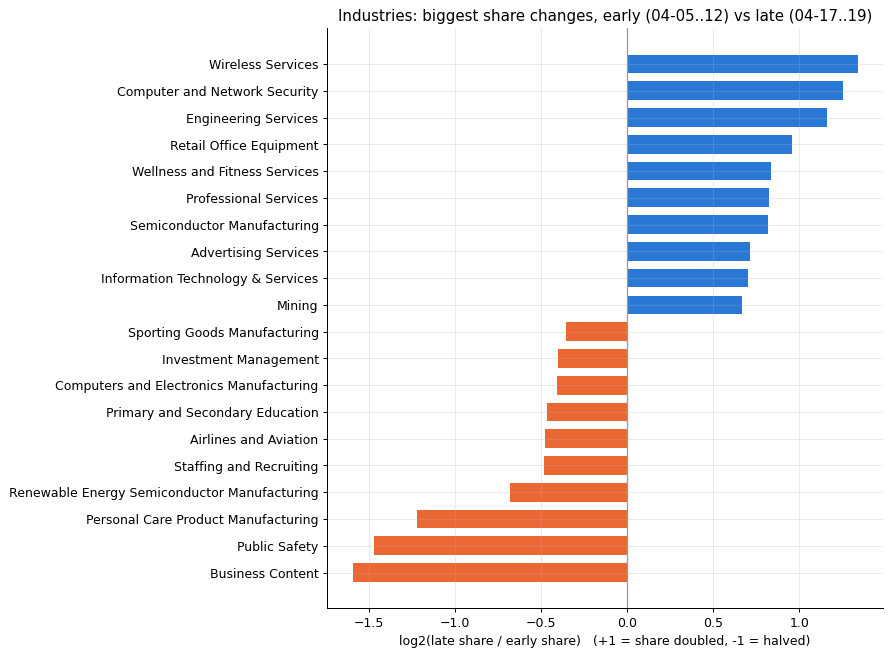

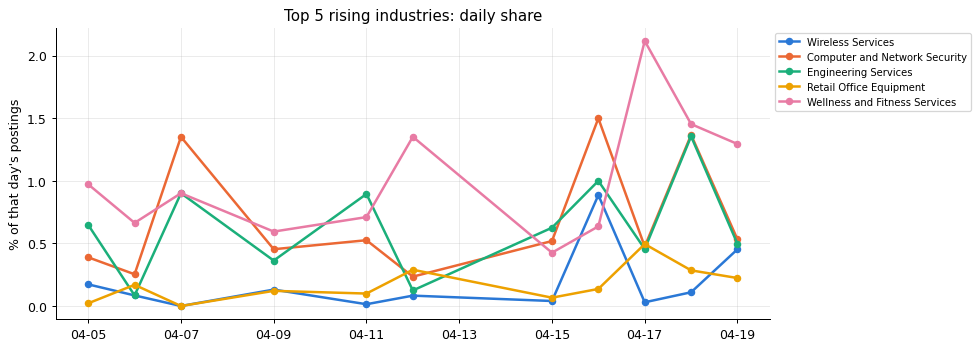

In [12]:
tab_ind, ds_ind = rising_table(win.merge(ind, on="job_id"), "industry_name", min_n=200)
print(f"{len(tab_ind)} industries with >= 200 postings in early+late")
display(tab_ind.head(12))
display(tab_ind.tail(8))
plot_movers(tab_ind, "Industries: biggest share changes, early (04-05..12) vs late (04-17..19)")
plot_daily_share(ds_ind, tab_ind.head(5).index, "Top 5 rising industries: daily share")

## B2. Job functions (LinkedIn's 35 job-function tags in `job_skills.csv`)

,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
skill_name,,,,,,,
Science,160,497,0.4284,0.6691,0.6403,0.0000,0.3091
Consulting,498,1461,1.3333,1.9670,0.5600,0.0000,0.6000
Research,721,1960,1.9304,2.6388,0.4504,0.0000,0.4636
Analyst,946,2434,2.5328,3.2770,0.3712,0.0000,0.0182
Advertising,164,419,0.4391,0.5641,0.3588,0.0062,0.2364
Supply Chain,296,734,0.7925,0.9882,0.3169,0.0013,0.4727
Distribution,98,242,0.2624,0.3258,0.3080,0.0696,0.3182
Strategy/Planning,293,706,0.7845,0.9505,0.2755,0.0054,-0.0818
Engineering,3351,7784,8.9719,10.4798,0.2240,0.0000,0.4909


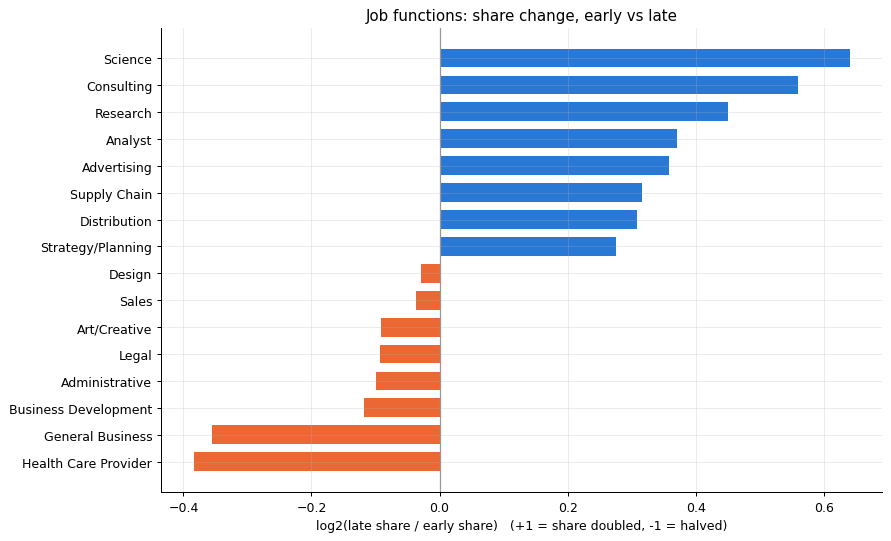

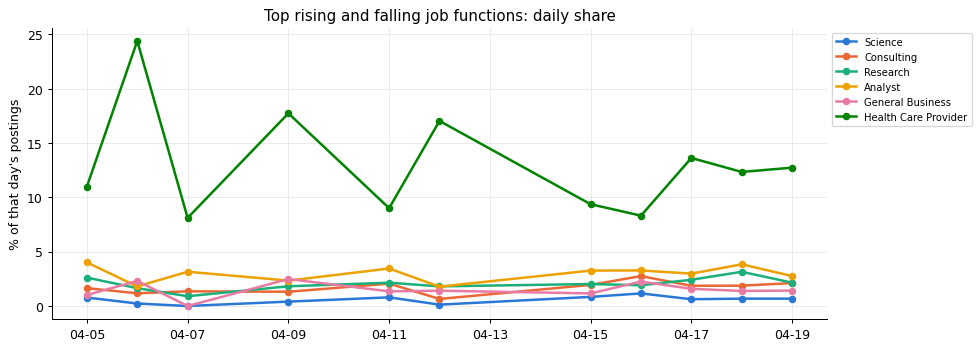

In [13]:
tab_fun, ds_fun = rising_table(win.merge(fun, on="job_id"), "skill_name", min_n=200)
display(tab_fun)
plot_movers(tab_fun, "Job functions: share change, early vs late", k=8)
plot_daily_share(ds_fun, list(tab_fun.head(4).index) + list(tab_fun.tail(2).index),
                 "Top rising and falling job functions: daily share")

## B3. Experience level, work type, remote

,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
formatted_experience_level,,,,,,,
Executive,320,778,0.8568,1.0474,0.2886,0.0023,0.4273
Associate,2507,5990,6.7122,8.0645,0.2646,0.0000,0.2455
Internship,398,931,1.0656,1.2534,0.2332,0.0063,0.3091
Director,1041,2297,2.7871,3.0925,0.1496,0.0047,0.3545
Entry level,10790,22965,28.8889,30.9185,0.0979,0.0000,0.3909
Mid-Senior level,12151,25098,32.5328,33.7902,0.0547,0.0000,0.5455
Not stated,10143,16217,27.1566,21.8334,-0.3148,0.0000,-0.6273


,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
formatted_work_type,,,,,,,
Other,109,344,0.2918,0.4631,0.6618,0.0000,0.3273
Contract,3049,7220,8.1633,9.7205,0.2517,0.0000,0.2636
Temporary,342,772,0.9157,1.0394,0.1816,0.0498,0.1909
Part-time,2910,6017,7.7912,8.1009,0.0561,0.0719,-0.0182
Full-time,30426,59055,81.4618,79.5075,-0.0350,0.0000,-0.1455
Internship,309,584,0.8273,0.7863,-0.0745,0.4675,-0.2636
Volunteer,205,284,0.5489,0.3824,-0.5225,0.0001,-0.6091


,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
remote,,,,,,,
Remote allowed,4479,9078,11.992,12.222,0.0273,0.267,-0.0727
Not remote / not stated,32871,65198,88.008,87.778,-0.0038,0.267,0.0727


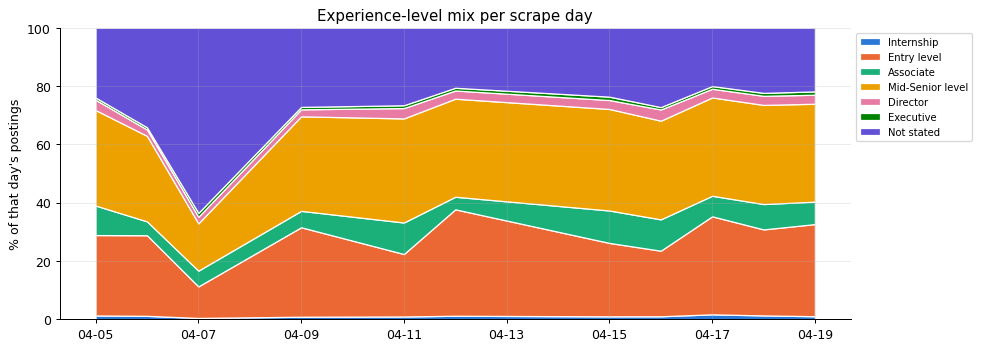

In [14]:
w = win.assign(formatted_experience_level=win.formatted_experience_level.fillna("Not stated"),
               remote=np.where(win.remote_allowed == 1, "Remote allowed", "Not remote / not stated"))
for col in ["formatted_experience_level", "formatted_work_type", "remote"]:
    t, ds = rising_table(w, col, min_n=100)
    display(t)

t, ds = rising_table(w, "formatted_experience_level", min_n=100)
order = ["Internship", "Entry level", "Associate", "Mid-Senior level", "Director", "Executive", "Not stated"]
ds = ds.reindex([o for o in order if o in ds.index])
fig, ax = plt.subplots()
ax.stackplot(ds.columns, 100 * ds.values, labels=ds.index, edgecolor="white", linewidth=1)
ax.set_ylabel("% of that day's postings"); ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.set_title("Experience-level mix per scrape day")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

## B4. Job titles

Titles are lower-cased and stripped of punctuation so that `CUSTOMER SERVICE REPRESENTATIVE` and
`Customer Service Representative` count as one.

53 titles with >= 80 postings in early+late


,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
title_norm,,,,,,,
licensed therapist for online counseling,0,94,0.0000,0.1266,6.5705,0.0000,0.5000
seasonal sales associate,1,86,0.0027,0.1158,4.8579,0.0000,0.5686
sales specialist,15,103,0.0402,0.1387,1.7475,0.0000,0.0367
sales executive,16,107,0.0428,0.1441,1.7120,0.0000,0.4237
patient care technician,17,93,0.0455,0.1252,1.4258,0.0001,0.4404
customer service representative,75,364,0.2008,0.4901,1.2796,0.0000,0.6091
warehouse associate,20,78,0.0535,0.1050,0.9453,0.0062,0.7273
data analyst,24,84,0.0643,0.1131,0.7944,0.0133,0.2909
retail sales associate,42,146,0.1124,0.1966,0.7936,0.0012,0.4545


,n_early,n_late,share_early_%,share_late_%,log2_ratio,p_value,spearman_rho
title_norm,,,,,,,
account executive,69,105,0.1847,0.1414,-0.3896,0.0830,-0.2909
operations manager,40,59,0.1071,0.0794,-0.4368,0.1429,-0.1909
medical assistant,46,64,0.1232,0.0862,-0.5197,0.0631,-0.1818
assistant store manager,123,169,0.3293,0.2275,-0.5350,0.0017,-0.3091
sales representative,51,65,0.1365,0.0875,-0.6449,0.0164,0.1273
operations assistant manager,48,57,0.1285,0.0767,-0.7462,0.0078,-0.2098
associate attorney,54,41,0.1446,0.0552,-1.3849,0.0000,-0.2182
sales manager,421,239,1.1272,0.3218,-1.8073,0.0000,0.1000
receptionist,142,54,0.3802,0.0727,-2.3784,0.0000,-0.0455


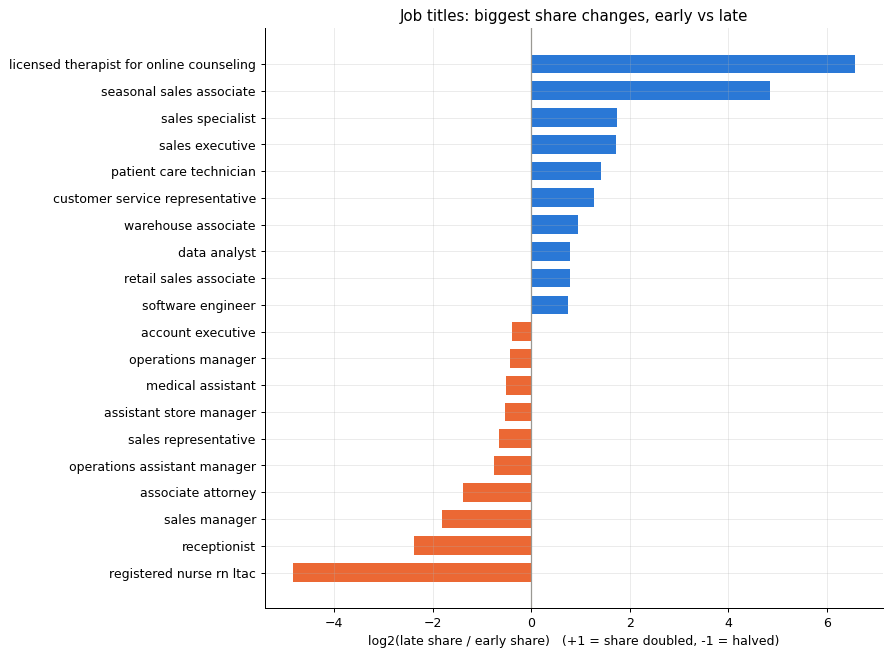

In [15]:
win["title_norm"] = (win.title.str.lower().str.replace(r"[^a-z0-9 ]+", " ", regex=True)
                       .str.replace(r"\s+", " ", regex=True).str.strip())
tab_title, ds_title = rising_table(win, "title_norm", min_n=80)
print(f"{len(tab_title)} titles with >= 80 postings in early+late")
display(tab_title.head(15))
display(tab_title.tail(10))
plot_movers(tab_title, "Job titles: biggest share changes, early vs late")

## B5. Employer concentration check

If one company posted most of a rising title's late-window jobs, the "rise" is that employer's bulk posting,
not broad demand. `top_company_share` = share of the title's **late** postings from its single largest company.

In [16]:
late = win[win.period == "late"]
def concentration(titles):
    rows = []
    for t in titles:
        g = late[late.title_norm == t]
        vc = g.company_name.value_counts()
        rows.append({"title_norm": t, "late_postings": len(g), "n_companies": g.company_name.nunique(),
                     "top_company": vc.index[0] if len(vc) else None,
                     "top_company_share": round(vc.iloc[0] / len(g), 3) if len(vc) else None})
    return pd.DataFrame(rows).set_index("title_norm")

conc = concentration(tab_title.head(15).index)
conc["flag"] = np.where(conc.top_company_share >= 0.5, "single-employer driven", "")
conc

,late_postings,n_companies,top_company,top_company_share,flag
title_norm,,,,,
licensed therapist for online counseling,94,1,BetterHelp,1.000,single-employer driven
seasonal sales associate,86,4,Men's Wearhouse,0.686,single-employer driven
sales specialist,103,18,White Cap,0.816,single-employer driven
sales executive,107,27,City Lifestyle,0.682,single-employer driven
patient care technician,93,9,DaVita Kidney Care,0.849,single-employer driven
customer service representative,364,100,Family Dollar,0.280,
warehouse associate,78,49,"Capstone Logistics, LLC",0.103,
data analyst,84,44,DataAnnotation,0.440,
retail sales associate,146,16,Verizon,0.384,


## B6. `all_job_post` categories over time (only 1,167 rows; read with care)

The 5 categories look sampled at ~equal sizes (220-240 each), so their shares are fixed by design; movement here is noise, not trend.


period,early,mid,late
category,,,
BUSINESS-DEVELOPMENT,0.208,0.267,0.190
FINANCE,0.223,0.127,0.208
HR,0.153,0.227,0.197
INFORMATION-TECHNOLOGY,0.196,0.233,0.206
SALES,0.220,0.147,0.200


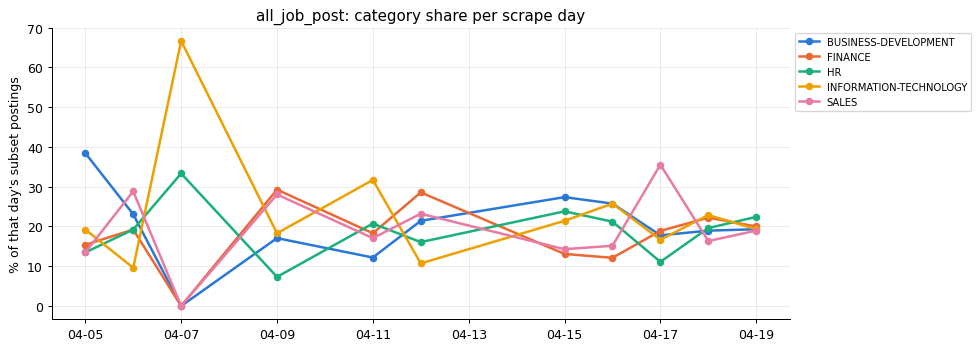

In [17]:
skw = skill.merge(win[["job_id", "day", "period"]], on="job_id")
sub_n = skw.groupby("period").job_id.nunique()
ct = pd.crosstab(skw.category, skw.period)
ct_share = (ct / sub_n).round(3)
display(ct_share[["early", "mid", "late"]])

ds = pd.crosstab(skw.category, skw.day, normalize="columns")
fig, ax = plt.subplots()
for c in ds.index:
    ax.plot(ds.columns, 100 * ds.loc[c], marker="o", ms=5, lw=2, label=c)
ax.set_ylabel("% of that day's subset postings"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.set_title("all_job_post: category share per scrape day")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
print("The 5 categories look sampled at ~equal sizes (220-240 each), so their shares are fixed by design;"
      " movement here is noise, not trend.")

## B7. Robustness: does the ranking hold if we date jobs by `original_listed_time` instead?

If the movers are real composition shifts, the industry ranking should look similar when periods are defined by the
first-posted date rather than the scrape date.

Spearman correlation of industry log2 ratios, listed_time vs original_listed_time: 0.994 (n=93)


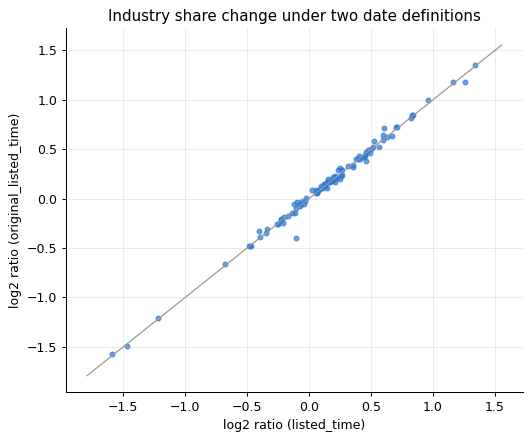

In [18]:
alt = win.copy()
alt["day"] = alt.original_listed_time.dt.floor("D")
alt["period"] = np.select([alt.day <= "2024-04-12", alt.day >= "2024-04-17"], ["early", "late"], "mid")
alt = alt[alt.day >= "2024-04-05"]
_N_PERIOD, _N_DAY = N_PERIOD, N_DAY
N_PERIOD = alt.groupby("period").job_id.nunique(); N_DAY = alt.groupby("day").job_id.nunique()
tab_ind_alt, _ = rising_table(alt.merge(ind, on="job_id"), "industry_name", min_n=200)
N_PERIOD, N_DAY = _N_PERIOD, _N_DAY

both = tab_ind[["log2_ratio"]].join(tab_ind_alt[["log2_ratio"]], rsuffix="_original_time", how="inner")
rho = both.log2_ratio.rank().corr(both.log2_ratio_original_time.rank())
print(f"Spearman correlation of industry log2 ratios, listed_time vs original_listed_time: {rho:.3f} (n={len(both)})")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(both.log2_ratio, both.log2_ratio_original_time, s=14, color=RISE, alpha=0.7)
lim = [both.min().min() - 0.2, both.max().max() + 0.2]
ax.plot(lim, lim, color=NEUTRAL, lw=1)
ax.set_xlabel("log2 ratio (listed_time)"); ax.set_ylabel("log2 ratio (original_listed_time)")
ax.set_title("Industry share change under two date definitions"); plt.tight_layout(); plt.show()

# Part C. Comparing with the 1.3M dataset (optional)

After running the 1.3M LinkedIn Jobs & Skills dataset (asaniczka, 2024) on the other computer, set the path to its
`linkedin_job_postings.csv` below. The cell then compares the **date ranges** and **overlapping job_ids**
(the 1.3M `job_link` URLs contain the LinkedIn job_id). Leave it as `None` to skip.

In [19]:
PATH_13M = None   # e.g. "../1.3M/linkedin_job_postings.csv"

if PATH_13M:
    big = pd.read_csv(PATH_13M, usecols=lambda c: c in {"job_link", "first_seen", "last_processed_time"})
    big["job_id"] = big.job_link.str.extract(r"(\d{6,})(?:/|\?|$)")[0].astype("Int64")
    big["first_seen"] = pd.to_datetime(big.first_seen, errors="coerce")
    print("1.3M first_seen range:", big.first_seen.min(), "->", big.first_seen.max())
    print("1.3M job_id range:", big.job_id.min(), "->", big.job_id.max())
    print("This dataset job_id range:", post.job_id.min(), "->", post.job_id.max())
    ids = set(big.job_id.dropna().astype("int64"))
    print(f"job_ids shared with postings.csv: {post.job_id.isin(ids).sum():,}")
    print(f"job_ids shared with all_job_post: {skill.job_id.isin(ids).sum():,}")

    fig, ax = plt.subplots()
    b = daily(big.first_seen.dropna()); n = daily(post.listed_time)
    ax.bar(b.index, b.values, color=FALL, label="1.3M first_seen")
    ax.bar(n.index, n.values, color=RISE, label="new dataset listed_time")
    ax.set_title("Daily postings: 1.3M vs new dataset"); ax.legend(); plt.tight_layout(); plt.show()
else:
    print("PATH_13M not set; skipping comparison.")

PATH_13M not set; skipping comparison.


# Conclusions

**Timeline (Part A)**
1. **Very narrow window.** `listed_time` is almost entirely **2024-04-05 to 2024-04-20** (about two weeks); 98.5% of `original_listed_time` falls in April 2024, with only a handful of rows as early as 2023-12. Despite the "2023-2024" name, this is one scrape snapshot from April 2024.
2. **The volume "increase" is a scraping artifact.** Daily counts are not smooth: 04-18 and 04-19 alone hold ~52% of rows, and 04-08, 04-10, 04-13 and 04-14 have zero rows even though jobs were still being first-posted on those days. Volume cannot tell us whether hiring rose or fell.
3. **The `all_job_post` subset** (1,167 rows) matches `postings.csv` 100% on `job_id`, falls in the same window, and has the same daily distribution. Its 5 categories are near-equal by design (220-240 each), so category trends inside it are not meaningful.

**Rising jobs (Part B), measured as share of each scrape day's postings, early (04-05..12) vs late (04-17..19)**
4. **Industries rising in share:** Computer & Network Security (0.38% to 0.90%), Engineering Services (0.39% to 0.88%), Wireless Services, Wellness & Fitness, Semiconductor Manufacturing, Advertising Services, IT & Services. **Falling:** Staffing & Recruiting (8.4% to 6.0%), Business Content, Public Safety, Personal Care Product Manufacturing.
5. **Job functions rising:** Science, Consulting, Research, Analyst, Supply Chain, Engineering, IT. **Falling:** Health Care Provider and General Business. Shifts are modest (mostly under 1.5x).
6. **Experience level:** the share with *no* stated level drops from 27% to 22%, which mechanically lifts every stated level. That is a data-completeness change between scrape batches, not a hiring shift.
7. **Job titles:** the biggest risers are mostly **single-employer bulk postings** (BetterHelp's online therapists, Men's Wearhouse seasonal sales, White Cap sales specialists, DaVita patient care technicians). Customer service representative, warehouse associate, retail sales associate, data analyst and software engineer rise across many employers. Sales manager, receptionist and one LTAC nurse posting fall sharply.

**How much to trust Part B**
- Two weeks and 11 scrape days is far too short for real labour-market trends. Daily shares jump around, and most Spearman ρ values are weak to moderate (0.2-0.6).
- B7 shows the ranking barely changes when jobs are dated by first-posted date (ρ = 0.99), but that is partly because the two date fields mostly agree. It rules out a date-field artifact; it does **not** rule out the scraper collecting different kinds of jobs in different batches.
- Best reading: these are **composition differences between scrape batches**. They are useful to know when the dataset is used as a test set (e.g. late batches are more tech/engineering and less staffing-agency heavy), not as evidence of rising demand.

**Overlap with the 1.3M dataset (Part C)**
8. The 1.3M dataset's dates and job_ids are not checked here. Run Part C with that file to get its date range and the exact `job_id` overlap before deciding whether to de-duplicate the test set. Different scrape windows alone do not guarantee independent records.